# Stage 3b – Scenario-Based Grouping

Turns the **links** found in Stage 3 into **scenarios** – groups of host events and IoT flows that belong to the same
story (for example *IoT flow → host accept → shell → connection to Host B*). Each scenario will later become exactly
one graph (Stage 4).

- **host** = host / process telemetry – Component 1 output (`Host.csv`, 138,945 events)
- **iot** = IoT network flows – Component 2 output (`IOT_Network_Flow.csv`, 59,415 flows)

Both files are **emulated component outputs**, not real recorded traffic.

**The grouping never uses a label.** It uses only structure: time, addresses, ports, process lineage and the Stage 3
links. The ground-truth label is read only to **evaluate** the grouping (Steps 4 – 8: are known chains kept
together? are scans one scenario?) and, afterwards, to **name** each scenario *normal* or *attack-containing* (Step 7).
The train / validation / test split is done in Stage 4.

Pipeline: rebuild the Stage 3 links → score every linked pair → group at a threshold T → **audit** (chains, SSH
sessions, scans, floods) → add the two missing link rules the audit exposes → choose T → name the scenarios → difficulty and shortcut audits → look at real scenarios → save.

**How to run:** use *Runtime → Run all*, or run the cells from top to bottom. Every cell checks what it needs and
tells you which earlier cell to run if something is missing.

**Outputs:** `scenario_assignments_v6v2.csv`, `scenario_summary_v6v2.csv`, `threshold_sweep_v6v2.csv`,
`links_stage3b_v6v2.csv` (saved next to the input files).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)

print("Libraries loaded successfully")
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

def need(*names):
    """Stop with a clear message if an earlier cell has not been run in this session."""
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(f"Not defined yet: {missing}. Run the cells above first (Runtime -> Run all, "
                           "or run the cells from the top in order).")

Libraries loaded successfully
python 3.12.4 | pandas 3.0.6 | numpy 2.5.3


## Step 1: Locate the data

- **Colab:** the cell tries to mount Google Drive and looks in `MyDrive/GNN/`; if the mount fails it looks in
  `/content` (upload the two CSV files there).
- **Local / VS Code:** start Jupyter from the project folder – the files are found in `D:/GNN`, `.` or `..`.

The files are expected under the names `Host.csv` (host) and `IOT_Network_Flow.csv` (iot); if you use other names,
change the two lists in the next cell. Open the CSVs only in Colab / VS Code: re-saving them in Excel rewrites the
`DD/MM/YYYY` timestamps.

In [2]:
from pathlib import Path

HOST_NAMES = ["Host.csv"]
IOT_NAMES = ["IOT_Network_Flow.csv"]

try:                                     # only works inside Colab
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted (" + type(e).__name__ + ") - looking in local / session folders")

DIRS = ["/content/drive/MyDrive/GNN", "/content", ".", "..", "D:/GNN"]

def find(names):
    for d in DIRS:
        for n in names:
            if (Path(d) / n).is_file():
                return d, n
    return None, None

DATA_DIR, HOST_FILE = find(HOST_NAMES)
_, IOT_FILE = find(IOT_NAMES)
if HOST_FILE is None or IOT_FILE is None:
    raise FileNotFoundError(f"host / iot csv not found in {DIRS}")
OUT = Path(DATA_DIR)
print("Data folder :", Path(DATA_DIR).resolve())
print("Host file   :", HOST_FILE)
print("IoT file    :", IOT_FILE)

Drive not mounted (ModuleNotFoundError) - looking in local / session folders
Data folder : D:\GNN
Host file   : Host.csv
IoT file    : IOT_Network_Flow.csv


## Pipeline code

Two small modules are written next to the notebook, so this notebook runs on its own (also in a fresh Colab session).

| File | Content |
|---|---|
| `relationship_mapping.py` | The Stage 3 code (loading, IoT↔host matching, host↔host, flow↔flow and process links) – unchanged |
| `scenario_grouping.py` | Pair scoring, grouping, the chain / SSH / burst audits, the two extra link rules and the scenario naming |

`scenario_grouping.py` reads the label only inside the audit functions and in `scenario_table`.

In [3]:
%%writefile relationship_mapping.py
"""Stage 3 - Cross-Domain Relationship Mapping: reusable pipeline code.

Used by the Stage 3 notebook (and imported by the Stage 3b notebook), so the
matching and linking rules are defined in one place only.

    from relationship_mapping import load_data, build_links_all
    host, iot = load_data(DATA_DIR, HOST_FILE, IOT_FILE)

Terminology
    host = host / process telemetry (one row = one host event)
    iot  = IoT network flows       (one row = one flow)
    node ids: "host:<row>" and "iot:<row>"  (row = 0-based position in the original file)

No ground-truth label column is read or used anywhere in this file.
"""

from pathlib import Path

import numpy as np
import pandas as pd

FMT = "%d/%m/%Y %H:%M:%S"
KEYS = ["src_ip", "dst_ip", "src_port", "dst_port", "protocol"]
NET_EVENTS = ["network_connect", "network_accept"]

W_MATCH = 30            # seconds, C1<->C2 correlation window (selected in the notebook, Step 4)
HOST_HOST_TOL = 5       # seconds, connect <-> accept on two hosts
FLOW_GAP = 15 * 60      # seconds, flow <-> flow continuity
ENTRY_GAP = 15 * 60     # seconds, accept -> child process
FALLBACK_GAP = 5        # seconds, accept -> child whose parent pid has no row
SERVICE_MIN_EVENTS = 30 # a pid with this many events (or PID 1) is a long-lived service


# --------------------------------------------------------------------------- loading
def load_data(data_dir, host_file, iot_file):
    """Read both files as text, parse timestamps strictly, add row ids."""
    host = pd.read_csv(Path(data_dir) / host_file, dtype=str, keep_default_na=False)
    iot = pd.read_csv(Path(data_dir) / iot_file, dtype=str, keep_default_na=False)
    host["ts"] = pd.to_datetime(host["timestamp"], format=FMT)
    iot["ts"] = pd.to_datetime(iot["timestamp"], format=FMT)
    host["row"] = np.arange(len(host))
    iot["row"] = np.arange(len(iot))
    for c in ["process_id", "parent_process_id"]:
        host[c] = host[c].astype("int64")
    return host, iot


def time_slice(df, start, end):
    return df[(df["ts"] >= pd.Timestamp(start)) & (df["ts"] < pd.Timestamp(end))]


# --------------------------------------------------------------------------- Section 1: IoT <-> host
def network_events(host):
    """Host connect/accept events in which the host itself is one endpoint."""
    net = host[host["event_type"].isin(NET_EVENTS)]
    return net[(net["src_ip"] == net["host_ip"]) | (net["dst_ip"] == net["host_ip"])]


def relevant_flows(iot, managed_ips):
    """IoT flows with a managed host at one end (the only ones that can match a host event)."""
    return iot[iot["src_ip"].isin(managed_ips) | iot["dst_ip"].isin(managed_ips)]


def candidate_pairs(rel, net):
    """All (flow, host event) pairs with the same IP pair, ports and protocol,
    in the direct form and in the reversed form (source/destination swapped)."""
    cols = KEYS + ["row", "ts", "event_type", "process_name", "host_ip", "process_id"]
    direct = rel.merge(net[cols], on=KEYS, suffixes=("", "_host"))
    direct["orient"] = "direct"
    swapped = net[cols].rename(columns={"src_ip": "dst_ip", "dst_ip": "src_ip",
                                        "src_port": "dst_port", "dst_port": "src_port"})
    reverse = rel.merge(swapped, on=KEYS, suffixes=("", "_host"))
    reverse["orient"] = "reversed"
    cand = pd.concat([direct, reverse], ignore_index=True).rename(
        columns={"row": "iot_row", "row_host": "host_row", "ts": "iot_ts", "ts_host": "host_ts"})
    cand["dt_sec"] = (cand["iot_ts"] - cand["host_ts"]).abs().dt.total_seconds()
    return cand


def one_to_one(df, a="iot_row", b="host_row", gap="dt_sec"):
    """Nearest timestamp wins; every item on either side is used at most once."""
    df = df.sort_values(gap, kind="stable")
    return df.drop_duplicates(a).drop_duplicates(b)


def match_iot_host(host, iot, managed_ips, window=W_MATCH):
    cand = candidate_pairs(relevant_flows(iot, managed_ips), network_events(host))
    return one_to_one(cand[cand["dt_sec"] <= window]).sort_values("iot_ts")


# --------------------------------------------------------------------------- Section 2: other links
def _node(prefix, rows):
    return prefix + ":" + pd.Series(rows).astype(str).to_numpy()


def _links(a_prefix, a_rows, b_prefix, b_rows, link_type, points, gap):
    return pd.DataFrame({"node_a": _node(a_prefix, a_rows), "node_b": _node(b_prefix, b_rows),
                         "link_type": link_type, "points": points, "gap_sec": np.asarray(gap, dtype=float)})


def host_host_links(host, managed_ips, tol=HOST_HOST_TOL):
    """connect on Host A  <->  accept on Host B, same tuple, within `tol` seconds."""
    net = network_events(host)
    cols = KEYS + ["row", "ts", "host_ip"]
    conn = net[(net["event_type"] == "network_connect") & (net["src_ip"] == net["host_ip"]) &
               net["dst_ip"].isin(managed_ips)][cols]
    acc = net[(net["event_type"] == "network_accept") & net["src_ip"].isin(managed_ips)][cols]
    m = conn.merge(acc, on=KEYS, suffixes=("_conn", "_acc"))
    m = m[m["host_ip_conn"] != m["host_ip_acc"]]
    m["gap"] = (m["ts_conn"] - m["ts_acc"]).abs().dt.total_seconds()
    m = m[m["gap"] <= tol].sort_values("gap", kind="stable").drop_duplicates("row_conn").drop_duplicates("row_acc")
    return _links("host", m["row_conn"], "host", m["row_acc"], "connect_accept", 3, m["gap"])


def flow_links(iot, gap=FLOW_GAP):
    """Consecutive flows that share a source and/or a destination within `gap` seconds.
    Same source AND destination is the strong link; source-only / destination-only are weak."""
    f = iot.sort_values(["ts", "row"], kind="stable")[["row", "ts", "src_ip", "dst_ip"]].reset_index(drop=True)

    def consecutive(keys):
        g = f.groupby(keys, sort=False)
        prev = g["row"].shift()
        d = (f["ts"] - g["ts"].shift()).dt.total_seconds()
        ok = prev.notna() & (d <= gap)
        return pd.DataFrame({"prev": prev[ok].astype(int), "cur": f.loc[ok, "row"], "gap": d[ok]})

    both = consecutive(["src_ip", "dst_ip"])
    seen = set(zip(both["prev"], both["cur"]))
    parts = [_links("iot", both["prev"], "iot", both["cur"], "flow_same_src_dst", 2, both["gap"])]
    for keys, ltype in ((["src_ip"], "flow_same_src"), (["dst_ip"], "flow_same_dst")):
        c = consecutive(keys)
        keep = np.array([(p, r) not in seen for p, r in zip(c["prev"], c["cur"])], dtype=bool)
        c = c[keep]
        parts.append(_links("iot", c["prev"], "iot", c["cur"], ltype, 1, c["gap"]))
    return pd.concat(parts, ignore_index=True)


def service_pids(host, min_events=SERVICE_MIN_EVENTS):
    """Long-lived services (many events) and PID 1: a shared service is NOT a shared entity."""
    counts = host["process_id"].value_counts()
    return set(counts[counts >= min_events].index) | {1}


def process_links(host, services):
    """Process-lineage links. Every link joins an earlier event to a later one."""
    h = host.sort_values(["ts", "row"], kind="stable").reset_index(drop=True)
    all_pids = set(h["process_id"])
    ps = h[h["event_type"] == "process_start"]
    acc = h[h["event_type"] == "network_accept"]
    links = []

    # (a) consecutive events of the same ephemeral (non-service) process
    eph = h[~h["process_id"].isin(services)]
    g = eph.groupby(["host_ip", "process_id"], sort=False)
    prev_row, prev_ts = g["row"].shift(), g["ts"].shift()
    d = (eph["ts"] - prev_ts).dt.total_seconds()
    ok = prev_row.notna() & (d <= ENTRY_GAP)
    links.append(_links("host", prev_row[ok].astype(int), "host", eph["row"][ok], "same_process", 2, d[ok]))

    def asof(left, right, key_left, key_right, by_left, tol):
        l = left[["row", "ts", "host_ip", key_left]].rename(columns={"row": "child_row", "ts": "child_ts", key_left: "_k"})
        r = right[["row", "ts", "host_ip", key_right]].rename(columns={"row": "prev_row", "ts": "prev_ts", key_right: "_k"})
        l = l.sort_values("child_ts", kind="stable")
        r = r.sort_values("prev_ts", kind="stable")
        by = ["host_ip", "_k"] if by_left else ["host_ip"]
        m = pd.merge_asof(l, r, left_on="child_ts", right_on="prev_ts", by=by,
                          direction="backward", tolerance=pd.Timedelta(seconds=tol))
        m = m.dropna(subset=["prev_row"])
        m["gap"] = (m["child_ts"] - m["prev_ts"]).dt.total_seconds()
        return m

    # (b) child process_start <-> latest event of its (non-service) parent
    ps_ns = ps[~ps["parent_process_id"].isin(services) & ps["parent_process_id"].isin(all_pids)]
    m = asof(ps_ns, h, "parent_process_id", "process_id", True, ENTRY_GAP)
    links.append(_links("host", m["prev_row"].astype(int), "host", m["child_row"], "parent_child", 2, m["gap"]))

    # (c) entry-to-child: child of a SERVICE process <-> nearest preceding accept handled by that service
    ps_sv = ps[ps["parent_process_id"].isin(services) & (ps["parent_process_id"] != 1)]
    m = asof(ps_sv, acc, "parent_process_id", "process_id", True, ENTRY_GAP)
    pts = np.where(m["gap"] <= 5, 3, 2)
    links.append(_links("host", m["prev_row"].astype(int), "host", m["child_row"], "entry_to_child", pts, m["gap"]))

    # (d) fallback: parent pid never appears as a row -> nearest preceding accept on the same host
    ps_or = ps[~ps["parent_process_id"].isin(all_pids)]
    m = asof(ps_or, acc, "parent_process_id", "process_id", False, FALLBACK_GAP)
    links.append(_links("host", m["prev_row"].astype(int), "host", m["child_row"], "fallback_accept", 2, m["gap"]))
    return pd.concat(links, ignore_index=True)


def build_links_all(host, iot, managed_ips, window=W_MATCH):
    """Every link used by the scenario grouping (Stage 3b): one row per link."""
    m = match_iot_host(host, iot, managed_ips, window)
    iot_host = _links("iot", m["iot_row"], "host", m["host_row"], "iot_host_match", 3, m["dt_sec"])
    parts = [iot_host, host_host_links(host, managed_ips), flow_links(iot),
             process_links(host, service_pids(host))]
    links = pd.concat(parts, ignore_index=True)
    return links.drop_duplicates(["node_a", "node_b", "link_type"]).reset_index(drop=True)

Overwriting relationship_mapping.py


In [4]:
%%writefile scenario_grouping.py
"""Stage 3b - Scenario-Based Grouping: reusable pipeline code.

Takes the links from Stage 3 (relationship_mapping.py) and turns them into
scenarios (groups of events that belong to the same story).

    import relationship_mapping as rm, scenario_grouping as sg
    nodes = sg.node_table(host, iot, managed_ips)
    pairs = sg.pair_scores(links_all, nodes, len(host))
    scenario = sg.group_scenarios(pairs, len(nodes), nodes["ts_s"].to_numpy(), T=3)

Grouping uses ONLY structure (time, addresses, process lineage and the Stage 3 links).
The ground-truth label is read only by the audit / labelling functions at the bottom,
which are used for validation, and the normal / attack-containing naming.
"""

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

GATE_GAP = 15 * 60       # seconds: two events further apart than this are never in one scenario
SHORT_GAP = 5 * 60       # seconds: "short gap" bonus point


# --------------------------------------------------------------------------- nodes and pairs
def node_table(host, iot, managed_ips):
    """One row per node. Index: host rows first (0..n_host-1), then iot rows (n_host..)."""
    n_host = len(host)
    iot_host_ip = np.where(iot["src_ip"].isin(managed_ips), iot["src_ip"],
                           np.where(iot["dst_ip"].isin(managed_ips), iot["dst_ip"], ""))
    nodes = pd.DataFrame({
        "node": np.concatenate(["host:" + host["row"].astype(str).to_numpy(), "iot:" + iot["row"].astype(str).to_numpy()]),
        "kind": ["host"] * n_host + ["iot"] * len(iot),
        "ts_s": np.concatenate([host["ts"].astype("datetime64[s]").astype("int64").to_numpy(),
                                iot["ts"].astype("datetime64[s]").astype("int64").to_numpy()]).astype(np.int64),
        "host_ip": np.concatenate([host["host_ip"].to_numpy(object), iot_host_ip.astype(object)]),
        "label": np.concatenate([host["label"].astype(int).to_numpy(), iot["label"].astype(int).to_numpy()]),
    })
    return nodes


def node_index(ids, n_host):
    kind = ids.str.split(":").str[0].to_numpy()
    row = ids.str.split(":").str[1].astype(int).to_numpy()
    return np.where(kind == "host", row, n_host + row)


def pair_scores(links, nodes, n_host):
    """Add up the evidence for every linked pair of events and apply the time gate.
    score = points of all links between the two events + 1 (same host) + 1 (gap under 5 min)."""
    df = pd.DataFrame({"a": node_index(links["node_a"], n_host), "b": node_index(links["node_b"], n_host),
                       "points": links["points"].to_numpy()})
    pair = df.groupby(["a", "b"], as_index=False)["points"].sum()
    ts, hip = nodes["ts_s"].to_numpy(), nodes["host_ip"].to_numpy(object)
    pair["gap"] = np.abs(ts[pair["b"]] - ts[pair["a"]])
    ha, hb = hip[pair["a"]], hip[pair["b"]]
    pair["same_host"] = ((ha == hb) & (ha != "")).astype(int)
    pair["short_gap"] = (pair["gap"] < SHORT_GAP).astype(int)
    pair["score"] = pair["points"] + pair["same_host"] + pair["short_gap"]
    return pair[pair["gap"] <= GATE_GAP].reset_index(drop=True)


# --------------------------------------------------------------------------- grouping
def group_scenarios(pairs, n_nodes, ts_s, T):
    """Link pairs with score >= T, take connected components, then split a component wherever
    two consecutive events are more than 15 minutes apart. Returns one scenario id per node."""
    acc = pairs[pairs["score"] >= T]
    graph = coo_matrix((np.ones(len(acc), dtype=np.int8), (acc["a"].to_numpy(), acc["b"].to_numpy())), shape=(n_nodes, n_nodes))
    _, comp = connected_components(graph, directed=False)
    order = np.lexsort((ts_s, comp))
    c, t = comp[order], ts_s[order]
    new_piece = np.ones(len(order), dtype=bool)
    new_piece[1:] = (c[1:] != c[:-1]) | ((t[1:] - t[:-1]) > GATE_GAP)
    sid = np.empty(n_nodes, dtype=np.int64)
    sid[order] = np.cumsum(new_piece) - 1
    return sid


def sweep_row(scenario, T):
    size = np.bincount(scenario)
    return {"T": T, "scenarios": len(size), "scenarios_2plus": int((size >= 2).sum()),
            "events_in_2plus": int(size[size >= 2].sum()), "singleton_share_%": round((size == 1).mean() * 100, 1),
            "mean_size_2plus": round(float(size[size >= 2].mean()), 2), "max_size": int(size.max()),
            "scenarios_over_200": int((size > 200).sum())}


# --------------------------------------------------------------------------- audits (structure only unless noted)
def recover_chains(host, iot, links, n_host):
    """IoT flow -> Host A accept -> (descendant process) connect -> Host B accept, found from exported fields only.
    Returns the four node indices of every chain."""
    ppid_of = dict(zip(host["process_id"].tolist(), host["parent_process_id"].tolist()))

    def lineage(pid):
        out, cur = {pid}, pid
        for _ in range(12):
            nxt = ppid_of.get(cur)
            if nxt is None or nxt == 1 or nxt in out:
                break
            out.add(nxt)
            cur = nxt
        return out

    ih = links[links["link_type"] == "iot_host_match"]
    ca = links[links["link_type"] == "connect_accept"]
    ts = host["ts"].astype("datetime64[s]").astype("int64").to_numpy()
    hrow = host["row"].to_numpy()
    h_iot = ih["node_a"].str.split(":").str[1].astype(int).to_numpy()
    h_hop = ih["node_b"].str.split(":").str[1].astype(int).to_numpy()
    hop_host = host["host_ip"].to_numpy()[h_hop]
    hop_pid = host["process_id"].to_numpy()[h_hop]
    hop_ts = ts[h_hop]
    by_host = {}
    for i, h in enumerate(hop_host):
        by_host.setdefault(h, []).append(i)
    by_host = {h: np.array(sorted(ix, key=lambda i: hop_ts[i])) for h, ix in by_host.items()}

    conn = ca["node_a"].str.split(":").str[1].astype(int).to_numpy()
    acc = ca["node_b"].str.split(":").str[1].astype(int).to_numpy()
    out = []
    pid_arr, host_arr = host["process_id"].to_numpy(), host["host_ip"].to_numpy()
    for c, a in zip(conn, acc):
        cand = by_host.get(host_arr[c])
        if cand is None:
            continue
        times = hop_ts[cand]
        j = np.searchsorted(times, ts[c], side="right") - 1
        lin = lineage(int(pid_arr[c]))
        while j >= 0 and ts[c] - times[j] <= 1800:
            if int(hop_pid[cand[j]]) in lin:
                k = cand[j]
                out.append((n_host + int(h_iot[k]), int(h_hop[k]), int(c), int(a)))
                break
            j -= 1
    return pd.DataFrame(out, columns=["iot_flow", "hop_accept", "connect", "accept_b"])


def ssh_fragmentation(host, scenario):
    """For every SSH accept (port 22), the next process started by one of its descendants within 15 min:
    is it in the same scenario?"""
    ppid_of = dict(zip(host["process_id"].tolist(), host["parent_process_id"].tolist()))
    acc = host[(host["event_type"] == "network_accept") & (host["dst_port"] == "22")]
    ps = host[host["event_type"] == "process_start"].sort_values(["ts", "row"])
    ts = host["ts"].astype("datetime64[s]").astype("int64").to_numpy()
    by_host = {h: g for h, g in ps.groupby("host_ip")}
    same = total = 0
    for r in acc.itertuples():
        g = by_host.get(r.host_ip)
        if g is None:
            continue
        lo = np.searchsorted(ts[g["row"].to_numpy()], ts[r.row], side="left")
        for pid, prow, pts in zip(g["process_id"].to_numpy()[lo:lo + 60], g["row"].to_numpy()[lo:lo + 60],
                                  ts[g["row"].to_numpy()][lo:lo + 60]):
            if pts - ts[r.row] > 900:
                break
            cur, anc = pid, set()
            for _ in range(12):
                par = ppid_of.get(cur)
                if par is None or par in anc:
                    break
                anc.add(par)
                cur = par
            if r.process_id in anc:
                total += 1
                same += int(scenario[prow] == scenario[r.row])
                break
    return same, total


def auc(score, positive):
    """ROC-AUC of a single numeric feature (rank formula); 0.5 = no information."""
    s = pd.Series(score).rank(method="average")
    pos = np.asarray(positive, dtype=bool)
    n1, n0 = pos.sum(), (~pos).sum()
    return float((s[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


# --------------------------------------------------------------------------- naming (uses the label)
def scenario_table(nodes, scenario):
    df = nodes.assign(scenario=scenario)
    g = df.groupby("scenario")
    t = pd.DataFrame({"n_events": g.size(), "n_host": g["kind"].apply(lambda s: (s == "host").sum()),
                      "n_iot": g["kind"].apply(lambda s: (s == "iot").sum()),
                      "start_s": g["ts_s"].min(), "end_s": g["ts_s"].max(),
                      "n_hosts": g["host_ip"].apply(lambda s: s[s != ""].nunique()),
                      "n_label1": g["label"].sum()})
    t["duration_s"] = t["end_s"] - t["start_s"]
    t["label1_share"] = t["n_label1"] / t["n_events"]
    t["type"] = np.where(t["n_label1"] > 0, "attack-containing", "normal")
    t["has_cross_domain_link"] = (t["n_host"] > 0) & (t["n_iot"] > 0)
    return t.reset_index()


# --------------------------------------------------------------------------- extra link found by the chain audit
def handoff_links(host, services, gap=GATE_GAP):
    """Service hand-off: a long-lived service (web server, listener) accepts a request and the SAME process then
    connects to the next host. Linked to the nearest preceding accept by that process (<= 15 min).
    This treats a normal proxy chain exactly like the attack chains, where the shell started by the accepting
    process is linked the same way (entry_to_child)."""
    h = host.sort_values(["ts", "row"], kind="stable")
    conn = h[(h["event_type"] == "network_connect") & h["process_id"].isin(services) & (h["process_id"] != 1)]
    acc = h[h["event_type"] == "network_accept"]
    l = conn[["row", "ts", "host_ip", "process_id"]].rename(columns={"row": "conn_row", "ts": "conn_ts", "process_id": "_k"})
    r = acc[["row", "ts", "host_ip", "process_id"]].rename(columns={"row": "acc_row", "ts": "acc_ts", "process_id": "_k"})
    m = pd.merge_asof(l.sort_values("conn_ts", kind="stable"), r.sort_values("acc_ts", kind="stable"),
                      left_on="conn_ts", right_on="acc_ts", by=["host_ip", "_k"], direction="backward",
                      tolerance=pd.Timedelta(seconds=gap)).dropna(subset=["acc_row"])
    return pd.DataFrame({"node_a": "host:" + m["acc_row"].astype(int).astype(str).to_numpy(),
                         "node_b": "host:" + m["conn_row"].astype(str).to_numpy(),
                         "link_type": "service_handoff", "points": 2,
                         "gap_sec": (m["conn_ts"] - m["acc_ts"]).dt.total_seconds().to_numpy()})


def burst_cohesion(host, scenario, event_type, attack_type, min_size=6, gap=GATE_GAP):
    """Validation (uses `type`): rows of one attack type hitting one host from one source in a burst should
    land in one scenario. Returns (bursts, share of bursts with >=90% of their rows in the largest scenario)."""
    d = host[(host["event_type"] == event_type) & (host["type"] == attack_type)].sort_values(["host_ip", "src_ip", "ts"])
    bursts = whole = 0
    for _, g in d.groupby(["host_ip", "src_ip"]):
        t = g["ts"].astype("datetime64[s]").astype("int64").to_numpy()
        cut = np.r_[0, np.where(np.diff(t) > gap)[0] + 1, len(t)]
        rows = g["row"].to_numpy()
        for a, b in zip(cut[:-1], cut[1:]):
            if b - a >= min_size:
                sc = scenario[rows[a:b]]
                bursts += 1
                whole += int(np.bincount(sc).max() / (b - a) >= 0.9)
    return bursts, whole


def remote_source_links(host, gap=GATE_GAP):
    """Same remote source: consecutive accepts on the same host from the same remote address within 15 min
    (port scans, password guessing and floods are many connections from one source). Services handle these,
    so no process link exists between them; the shared communication endpoint is the evidence."""
    acc = host[(host["event_type"] == "network_accept") & (host["src_ip"] != "-")].sort_values(["ts", "row"], kind="stable")
    g = acc.groupby(["host_ip", "src_ip"], sort=False)
    prev = g["row"].shift()
    d = (acc["ts"] - g["ts"].shift()).dt.total_seconds()
    ok = prev.notna() & (d <= gap)
    return pd.DataFrame({"node_a": "host:" + prev[ok].astype(int).astype(str).to_numpy(),
                         "node_b": "host:" + acc["row"][ok].astype(str).to_numpy(),
                         "link_type": "same_remote_source", "points": 2, "gap_sec": d[ok].to_numpy()})

Overwriting scenario_grouping.py


In [5]:
import importlib, os, sys
sys.path.insert(0, ".")
for _f in ("relationship_mapping.py", "scenario_grouping.py"):
    if not os.path.isfile(_f):
        raise FileNotFoundError(_f + " is missing: run the two '%%writefile' cells above first (they create the module files).")
import relationship_mapping as rm
import scenario_grouping as sg
importlib.reload(rm); importlib.reload(sg)
print("modules imported | gate gap =", sg.GATE_GAP, "s | short-gap bonus below", sg.SHORT_GAP, "s")

modules imported | gate gap =

 900 s | short-gap bonus below 300 s


## Step 2: Load the data and rebuild the Stage 3 links

The Stage 3 link builder takes about a second, so the links are simply rebuilt (nothing has to be uploaded from
Stage 3). If `links_all_v6v2.csv` from Stage 3 is in the folder, the rebuilt links are compared with it.

In [6]:
need('rm', 'sg', 'DATA_DIR', 'HOST_FILE', 'IOT_FILE', 'OUT')
# ==========================================
# STEP 2: LOAD DATA AND REBUILD STAGE 3 LINKS
# ==========================================
host, iot = rm.load_data(DATA_DIR, HOST_FILE, IOT_FILE)
managed_ips = set(host["host_ip"])
services = rm.service_pids(host)

stage3_links = rm.build_links_all(host, iot, managed_ips, rm.W_MATCH)
print("host events:", len(host), "| iot flows:", len(iot), "| nodes:", len(host) + len(iot))
print("Stage 3 links rebuilt:", len(stage3_links))
display(stage3_links["link_type"].value_counts().to_frame("links"))

saved = OUT / "links_all_v6v2.csv"
if saved.is_file():
    old = pd.read_csv(saved)
    print("\nidentical to the saved Stage 3 links_all_v6v2.csv:",
          len(old) == len(stage3_links) and old["link_type"].value_counts().to_dict() == stage3_links["link_type"].value_counts().to_dict())

host events: 138945 | iot flows: 59415 | nodes: 198360
Stage 3 links rebuilt: 91463


,links
link_type,
same_process,47488
entry_to_child,11877
connect_accept,8171
flow_same_src_dst,7411
flow_same_src,5892
iot_host_match,5620
parent_child,3286
flow_same_dst,1023
fallback_accept,695



identical to the saved Stage 3 links_all_v6v2.csv: True


**Result:** the Stage 3 links are rebuilt – **91,463 links in nine types** – and match the saved `links_all_v6v2.csv`
from Stage 3 exactly. These are the only evidence the grouping starts from.

## Step 3: Score every linked pair

Several links can join the same two events, and a link alone does not say how strong the relationship is. For every
linked pair the evidence is added up, and a **time gate** is applied (events more than 15 minutes apart are never in
one scenario):

| Evidence | Points |
|---|---|
| Points of the Stage 3 links between the pair (`iot_host_match` 3, `connect_accept` 3, `entry_to_child` 3 / 2, `parent_child` 2, `same_process` 2, `flow_same_src_dst` 2, `fallback_accept` 2, `flow_same_src` / `flow_same_dst` 1) | added up |
| Both events are on the same host | +1 |
| The two events are less than 5 minutes apart | +1 |

Two events end up in the same scenario when their **score ≥ T**. Scenarios are the connected groups of such pairs.
Afterwards a scenario is cut wherever two consecutive events are more than 15 minutes apart.

In [7]:
need('host', 'iot', 'managed_ips', 'stage3_links')
# ==========================================
# STEP 3: NODES AND PAIR SCORES (Stage 3 links only)
# ==========================================
nodes = sg.node_table(host, iot, managed_ips)
ts_s = nodes["ts_s"].to_numpy()
pairs_a = sg.pair_scores(stage3_links, nodes, len(host))

print("nodes:", len(nodes), "| linked pairs inside the 15-minute gate:", len(pairs_a))
dist = pairs_a["score"].value_counts().sort_index().to_frame("pairs")
dist["cumulative_pairs_with_score_>=_T"] = dist["pairs"][::-1].cumsum()[::-1]
display(dist)

nodes: 198360 | linked pairs inside the 15-minute gate: 91463


,pairs,cumulative_pairs_with_score_>=_T
score,,
1,4515,91463
2,2426,86948
3,980,84522
4,66316,83542
5,17226,17226


**Result:** all 91,463 linked pairs are inside the 15-minute gate. Most pairs are strong: **84,522 have a score of 3 or
more** (66,316 score 4 and 17,226 score 5). The 4,515 pairs with score 1 and the 2,426 with score 2 are the weak
same-device / same-destination flow links; they only join events at T = 2.

## Step 4: Audit the grouping against known chains, scans and floods

Before choosing a threshold, the grouping is tested against things that **must** come out right. These checks use the
label / attack type *only to evaluate* the result:

- **Attack chains** – IoT flow → Host A accept → shell → connect → Host B accept, found from the exported fields
  (process lineage). The share kept as **one** scenario should be high.
- **Normal look-alike chains** – the same shape, but legitimate (a web server calling an API). The attack chain must
  not be the *only* connected multi-hop shape.
- **SSH sessions** – the process started after an SSH accept should stay with that accept (if more than 10 – 15 % are
  separated, the data would need a change).
- **Scans, password guessing and floods** – many connections from one source to one host in a burst: should be **one**
  scenario each.

In [8]:
need('host', 'iot', 'nodes', 'ts_s', 'stage3_links')
# ==========================================
# STEP 4: AUDIT FUNCTION
# ==========================================
chains = sg.recover_chains(host, iot, stage3_links, len(host))
chain_is_attack = host["label"].astype(int).to_numpy()[chains["connect"]] == 1      # label used only to name the chain
print("multi-hop chains recovered from exported fields:", len(chains))
print("  attack-labelled pivot:", int(chain_is_attack.sum()), "| legitimate:", int((~chain_is_attack).sum()))

def audit(links, T, label):
    pairs = sg.pair_scores(links, nodes, len(host))
    sc = sg.group_scenarios(pairs, len(nodes), ts_s, T)
    r = sg.sweep_row(sc, T)
    whole = ((sc[chains["iot_flow"]] == sc[chains["hop_accept"]]) & (sc[chains["hop_accept"]] == sc[chains["connect"]]) &
             (sc[chains["connect"]] == sc[chains["accept_b"]]))
    same, total = sg.ssh_fragmentation(host, sc)
    sb, pb, db = (sg.burst_cohesion(host, sc, "network_accept", t) for t in ("scanning", "password", "dos"))
    return sc, {"links": label, "T": T, "scenarios_2plus": r["scenarios_2plus"], "events_in_2plus": r["events_in_2plus"],
                "mean_size": r["mean_size_2plus"], "max_size": r["max_size"], "over_200": r["scenarios_over_200"],
                "attack_chains_whole_%": round(whole[chain_is_attack].mean() * 100, 1),
                "normal_chains_whole_%": round(whole[~chain_is_attack].mean() * 100, 1),
                "scan_bursts_whole": f"{sb[1]}/{sb[0]}", "password_bursts_whole": f"{pb[1]}/{pb[0]}",
                "flood_bursts_whole": f"{db[1]}/{db[0]}", "ssh_apart_%": round((1 - same / total) * 100, 1)}

rows_a = [audit(stage3_links, T, "A: Stage 3 links")[1] for T in (2, 3, 4)]
display(pd.DataFrame(rows_a))

multi-hop chains recovered from exported fields: 656
  attack-labelled pivot: 145 | legitimate: 511


,links,T,scenarios_2plus,events_in_2plus,mean_size,max_size,over_200,attack_chains_whole_%,normal_chains_whole_%,scan_bursts_whole,password_bursts_whole,flood_bursts_whole,ssh_apart_%
0,A: Stage 3 links,2,15622,102556,6.56,118,0,95.2,0.0,0/163,0/63,60/123,1.6
1,A: Stage 3 links,3,13576,98098,7.23,118,0,95.2,0.0,0/163,0/63,60/123,1.6
2,A: Stage 3 links,4,13964,97506,6.98,118,0,56.6,0.0,0/163,0/63,60/123,2.6


**Result:** 656 multi-hop chains are recovered from the exported fields (145 with an attack-labelled pivot, 511
legitimate). The audit finds **two gaps** in the Stage 3 links, both visible at every threshold:

1. **Normal chains split.** At T = 3, 95.2 % of the attack chains stay whole, but **0 % of the legitimate chains do**.
   A web server accepts an IoT request and then calls the next host, but the two events share only a *service*
   process (not a shared entity), so nothing links them. A connected IoT → host → host scenario would then mean "attack"
   by construction – a shortcut for the model.
2. **Scans, password guessing and floods fall apart.** **0 of 163** port-scan bursts, **0 of 63** password-guessing
   bursts and only 60 of 123 flood bursts come out as one scenario: many connections from one outside address have
   no process or flow link between them, so each probe becomes its own single event.

On the good side, SSH sessions are not a problem: only **1.6 %** of SSH-started processes end up in a different scenario
at T = 3, far below the 10 – 15 % that would call for a data change. No scenario is oversized (maximum 118 events).

## Step 5: Add the two missing link rules and compare

Both rules are natural relationships that were already named in the grouping design (shared process / communication
endpoint); they are added **to the grouping**, not to the data:

| New link | Rule | Points |
|---|---|---|
| `service_handoff` | a long-lived service (web server, listener) accepts a request and the **same process** then connects to the next host; linked to the nearest earlier accept by that process (≤ 15 min). This is the same relationship as `entry_to_child`, which already links the shell an attacker starts. | 2 |
| `same_remote_source` | consecutive accepts on the **same host from the same remote address** within 15 min (a scan, a password-guessing run or a flood) | 2 |

The comparison below runs all three link sets (A = Stage 3 links, B = A + hand-off, C = B + same remote source) at
T = 2, 3 and 4.

In [9]:
need('host', 'iot', 'nodes', 'ts_s', 'services', 'stage3_links', 'rows_a', 'audit')
# ==========================================
# STEP 5: THE TWO NEW LINK RULES + FULL SWEEP
# ==========================================
handoff = sg.handoff_links(host, services)
remote = sg.remote_source_links(host)
print("service_handoff links    :", len(handoff), "| median gap %.0f s" % handoff["gap_sec"].median())
print("same_remote_source links :", len(remote), "| median gap %.0f s" % remote["gap_sec"].median())
acc_src = host.set_index("row").loc[handoff["node_a"].str[5:].astype(int), "src_ip"]
print("hand-off links that start from an IoT-device accept: %.1f%%" % (acc_src.str.startswith("10.30.").mean() * 100))

links_b = pd.concat([stage3_links, handoff], ignore_index=True)
links_c = pd.concat([stage3_links, handoff, remote], ignore_index=True)

sweep_rows = rows_a[:]
for links, name in ((links_b, "B: + service hand-off"), (links_c, "C: + same remote source")):
    sweep_rows += [audit(links, T, name)[1] for T in (2, 3, 4)]
sweep = pd.DataFrame(sweep_rows)
display(sweep)
sweep.to_csv(OUT / "threshold_sweep_v6v2.csv", index=False)
print("saved", OUT / "threshold_sweep_v6v2.csv")

service_handoff links    : 1219 | median gap 27 s
same_remote_source links : 6413 | median gap 4 s
hand-off links that start from an IoT-device accept: 73.7%


,links,T,scenarios_2plus,events_in_2plus,mean_size,max_size,over_200,attack_chains_whole_%,normal_chains_whole_%,scan_bursts_whole,password_bursts_whole,flood_bursts_whole,ssh_apart_%
0,A: Stage 3 links,2,15622,102556,6.56,118,0,95.2,0.0,0/163,0/63,60/123,1.6
1,A: Stage 3 links,3,13576,98098,7.23,118,0,95.2,0.0,0/163,0/63,60/123,1.6
2,A: Stage 3 links,4,13964,97506,6.98,118,0,56.6,0.0,0/163,0/63,60/123,2.6
3,B: + service hand-off,2,15124,102842,6.80,118,0,96.6,88.8,0/163,0/63,60/123,1.6
4,B: + service hand-off,3,13078,98384,7.52,118,0,96.6,88.8,0/163,0/63,60/123,1.6
5,B: + service hand-off,4,13596,97595,7.18,118,0,57.2,69.7,0/163,0/63,60/123,2.6
6,C: + same remote source,2,14826,106153,7.16,118,0,96.6,89.8,163/163,63/63,123/123,1.5
7,C: + same remote source,3,12780,101695,7.96,118,0,96.6,89.8,163/163,63/63,123/123,1.5
8,C: + same remote source,4,13565,100846,7.43,118,0,57.2,69.9,163/163,63/63,123/123,2.6


saved D:\GNN\threshold_sweep_v6v2.csv


**Result:** both gaps close.

- **Hand-off rule (B):** 1,219 new links; legitimate chains kept whole rise from 0 % to **88.8 %** (attack chains 96.6 %),
  so a connected multi-hop scenario is no longer a giveaway. 73.7 % of these new links start from an IoT-device accept,
  so they are mostly the real proxy relationships, not coincidences.
- **Same-remote-source rule (C):** 6,413 new links; scan bursts **163 / 163**, password-guessing bursts **63 / 63** and
  flood bursts **123 / 123** now each come out as one scenario. No scenario exceeds 118 events, so nothing merges into a
  giant group.

**Threshold:** T = 2 adds only the weak same-source flow links (14,826 scenarios against 12,780 at T = 3). **T = 4 breaks the
chains**: attack chains kept whole fall from 96.6 % to 57.2 % and legitimate chains from 89.8 % to 69.9 %, because the
minutes-long gap between the steps of a chain loses its short-gap bonus. **T = 3 with link set C is selected** – the
smallest threshold that keeps chains, scans and floods together without relying on weak links alone. The threshold is
chosen from these structural checks, not from any model result.

## Step 6: Final grouping (link set C, T = 3)

link set C: 99095 links | pairs with score >= 3: 92154
all scenarios (incl. single events): 109445
scenarios with at least 2 events   : 12780 | events inside them: 101695 of 198360 (51.3%)
single-event scenarios             : 96665
size of scenarios with >= 2 events: mean 7.96 | median 6 | 95th pct 17 | max 118


,scenarios
2,108
3,2287
4-5,3731
6-10,3959
11-20,2233
21-50,407
51-200,55


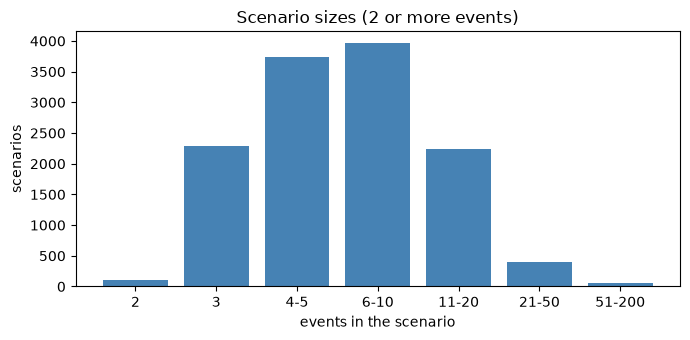

In [10]:
need('host', 'nodes', 'links_c', 'audit', 'ts_s')
# ==========================================
# STEP 6: FINAL GROUPING
# ==========================================
T_FINAL = 3
pairs_c = sg.pair_scores(links_c, nodes, len(host))
scenario, _ = audit(links_c, T_FINAL, "C")[0], None
size = np.bincount(scenario)

print("link set C:", len(links_c), "links | pairs with score >= 3:", int((pairs_c['score'] >= T_FINAL).sum()))
print("all scenarios (incl. single events):", len(size))
print("scenarios with at least 2 events   :", int((size >= 2).sum()), "| events inside them:", int(size[size >= 2].sum()),
      f"of {len(nodes)} ({size[size >= 2].sum() / len(nodes) * 100:.1f}%)")
print("single-event scenarios             :", int((size == 1).sum()))
print("size of scenarios with >= 2 events: mean %.2f | median %d | 95th pct %d | max %d" %
      (size[size >= 2].mean(), np.median(size[size >= 2]), np.percentile(size[size >= 2], 95), size.max()))

bins = pd.cut(pd.Series(size[size >= 2]), [1, 2, 3, 5, 10, 20, 50, 200], labels=["2", "3", "4-5", "6-10", "11-20", "21-50", "51-200"])
display(bins.value_counts().sort_index().to_frame("scenarios"))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(bins.value_counts().sort_index().index.astype(str), bins.value_counts().sort_index().values, color="steelblue")
ax.set_xlabel("events in the scenario"); ax.set_ylabel("scenarios"); ax.set_title("Scenario sizes (2 or more events)")
plt.tight_layout(); plt.show()

**Result:** the 198,360 events form **12,780 scenarios with at least 2 events** (101,695 events, 51.3 % of all events;
mean 8.0, median 6, 95th percentile 17, maximum 118). The other events are **single-event scenarios** with no link
(96,665): background traffic with no relationship, set aside because a graph needs at least 2 events and 1 link. Only 108
scenarios have exactly 2 events; most have 3 – 10 events (2,287 with 3, 3,731 with 4 – 5, 3,959 with 6 – 10), and 2,695 are
larger (11 – 118 events): the long sessions, chains, scans and floods.

## Step 7: Name the scenarios (the only place labels are read for building the data sets)

- A scenario is **normal** if every event in it has `label = 0`, and **attack-containing** if at least one event has
  `label = 1`. Scenarios with a single event are excluded (a graph needs at least 2 events and 1 link).
- The **split into train / validation / test is not done here**: it is done by scenario at the start of Stage 4, because the
  feature scaler must be fitted on the training scenarios only. This notebook only provides the scenario names.

In [11]:
need('nodes', 'scenario')
# ==========================================
# STEP 7: NAME THE SCENARIOS
# ==========================================
tbl = sg.scenario_table(nodes, scenario)
inc = tbl[tbl["n_events"] >= 2]

print("scenarios with >= 2 events:", len(inc))
display(inc.groupby("type").size().to_frame("scenarios"))
print("attack-containing share of scenarios: %.1f%%" % ((inc["type"] == "attack-containing").mean() * 100))
print("label-1 events in normal scenarios:", int(inc[inc["type"] == "normal"]["n_label1"].sum()), "(must be 0)")
print("label-1 events left in single-event scenarios:", int(tbl[tbl["n_events"] == 1]["n_label1"].sum()),
      "(background rows labelled attack with no surrounding structure)")

scenarios with >= 2 events: 12780


,scenarios
type,
attack-containing,2000
normal,10780


attack-containing share of scenarios: 15.6%
label-1 events in normal scenarios: 0 (must be 0)
label-1 events left in single-event scenarios: 9998 (background rows labelled attack with no surrounding structure)


**Result:** of 12,780 scenarios, **10,780 are normal and 2,000 attack-containing (15.6 %)**. No normal scenario contains a
`label = 1` event, as required. 9,998 attack-labelled events remain as single events: these are background rows labelled
attack with no surrounding relationship, so they cannot form a graph and are not part of the test set. The split of the
normal scenarios into train / validation / test is made in Stage 4.

### Can the graphs be made bigger by keeping only larger scenarios?

Many scenarios are small, so it is tempting to train only on larger ones. The table shows what that would do: how
many normal and attack-containing scenarios remain at each minimum size, and how the attack share changes.

In [12]:
need('inc')
# ==========================================
# STEP 7b: WHAT A MINIMUM-SIZE FILTER WOULD DO
# ==========================================
rows = []
for m in (2, 3, 4, 5, 6, 8):
    s = inc[inc["n_events"] >= m]
    rows.append({"min_events": m, "normal": int((s["type"] == "normal").sum()),
                 "attack_containing": int((s["type"] == "attack-containing").sum()),
                 "attack_share_%": round((s["type"] == "attack-containing").mean() * 100, 1),
                 "normal_mean_size": round(s[s["type"] == "normal"]["n_events"].mean(), 1),
                 "attack_mean_size": round(s[s["type"] == "attack-containing"]["n_events"].mean(), 1)})
display(pd.DataFrame(rows))
print("normal scenarios by exact size:", inc[inc["type"] == "normal"]["n_events"].value_counts().sort_index().head(6).to_dict())

,min_events,normal,attack_containing,attack_share_%,normal_mean_size,attack_mean_size
0,2,10780,2000,15.6,7.7,9.4
1,3,10778,1894,14.9,7.7,9.8
2,4,8542,1843,17.7,8.9,10.0
3,5,6904,1509,17.9,10.1,11.3
4,6,5464,1190,17.9,11.4,13.0
5,8,3489,754,17.8,14.3,16.9


normal scenarios by exact size: {2: 2, 3: 2236, 4: 1638, 5: 1440, 6: 1374, 7: 601}


**Result:** a minimum-size filter would change the balance very little: the attack share stays between 14.9 % and 17.9 % at every
minimum size (2 to 8 events), and the mean size is similar for the two types (normal 7.7, attack 9.4 at 2 or more
events). Only 2 normal scenarios have 2 events, and the sizes then run 3 (2,236), 4 (1,638), 5 (1,440), 6 (1,374), 7 (601) and
upwards. So a size filter is not needed to give the model larger graphs, and it is **not used** for the main experiment;
results are reported by size band instead.

## Step 8: Two audits that protect the training results

**Difficulty audit** – how much of an attack-containing scenario is actually flagged? A scenario in which only one
event is labelled attack, inside an otherwise ordinary shape, cannot be told apart from a normal one.

**Shortcut audit** – can a trivial property of the scenario (its size, duration, number of hosts …) separate attack
from normal by itself? Each is scored as a single feature by its **ROC-AUC** (0.5 = no information, 1.0 = perfect
separation). Anything above about 0.8 would be a shortcut the model could learn instead of the relationships.

In [13]:
need('inc')
# ==========================================
# STEP 8: DIFFICULTY AND SHORTCUT AUDITS
# ==========================================
atk = inc[inc["type"] == "attack-containing"]
nrm = inc[inc["type"] == "normal"]

share_bins = pd.cut(atk["label1_share"], [0, 0.5, 0.9999, 1.0], labels=["up to 50% flagged", "51 - 99% flagged", "100% flagged"])
print("attack-containing scenarios by share of events labelled attack:")
display(share_bins.value_counts().sort_index().to_frame("scenarios"))
print("attack scenarios with exactly ONE flagged event:", int((atk["n_label1"] == 1).sum()),
      f"({(atk['n_label1'] == 1).mean() * 100:.1f}%)")

print("\nscenario size   : normal mean %.2f (max %d) | attack mean %.2f (max %d)" %
      (nrm["n_events"].mean(), nrm["n_events"].max(), atk["n_events"].mean(), atk["n_events"].max()))
y = (inc["type"] == "attack-containing")
shortcut = pd.DataFrame({"single feature": ["n_events", "duration_s", "n_hosts", "n_iot", "n_host", "has_cross_domain_link"]})
shortcut["ROC-AUC"] = [round(sg.auc(inc[c].astype(float), y), 3) for c in shortcut["single feature"]]
display(shortcut)
print("any single feature above 0.8:", bool((shortcut["ROC-AUC"] > 0.8).any()))

attack-containing scenarios by share of events labelled attack:


,scenarios
label1_share,
up to 50% flagged,123
51 - 99% flagged,183
100% flagged,1694


attack scenarios with exactly ONE flagged event: 41 (2.1%)

scenario size   : normal mean 7.69 (max 40) | attack mean 9.41 (max 118)


,single feature,ROC-AUC
0,n_events,0.561
1,duration_s,0.504
2,n_hosts,0.402
3,n_iot,0.543
4,n_host,0.533
5,has_cross_domain_link,0.517


any single feature above 0.8: False


**Result:** the attack-containing scenarios are overwhelmingly real attack structure – **1,694 of 2,000 (84.7 %) have every
event flagged** and only **41 (2.1 %) have a single flagged event**. So the worry that background label noise would make a
large share of the test attacks impossible to detect is **not** borne out; those rows are single events and were excluded.

**No single scenario property is a shortcut:** the highest ROC-AUC is **0.561 (size)**, then 0.543 (number of IoT events),
0.533 (host events), 0.517 (cross-domain flag) and 0.504 (duration), all far below the 0.8 warning level. The number of
hosts is 0.402 (attack scenarios touch somewhat fewer hosts, which works as 0.598 in the other direction); it is
checked again in Stage 5. Normal scenarios average 7.7 events (maximum 40) and attack-containing ones 9.4 (maximum 118).
For the report, a **size-only baseline** should still be included, so the model must beat it to show it learns more than size.

## Step 9: Read real scenarios

A table cannot show whether a scenario makes sense, so six are printed event by event: an attack chain, a legitimate
chain, a port scan, a password-guessing run, a flood and an ordinary pair. Each line is one event.

In [14]:
need('host', 'iot', 'scenario', 'ts_s', 'tbl', 'chains', 'chain_is_attack', 'inc', 'rm')
# ==========================================
# STEP 9: LOOK AT REAL SCENARIOS
# ==========================================
def show(sid, limit=14):
    idx = np.where(scenario == sid)[0]
    idx = idx[np.argsort(ts_s[idx], kind="stable")]
    t = tbl.loc[tbl["scenario"] == sid].iloc[0]
    print(f"--- scenario {sid}: {t.n_events} events, {t.duration_s:.0f}s, {t.type}")
    for i in idx[:limit]:
        if i < len(host):
            r = host.iloc[i]
            tup = f" {r.src_ip}->{r.dst_ip}:{r.dst_port}" if r.event_type in rm.NET_EVENTS else ""
            print(f"  {r.timestamp} | {r.host_ip:10s} | {r.process_name}[{r.process_id}] {r.event_type}{tup} | label {r.label}")
        else:
            r = iot.iloc[i - len(host)]
            print(f"  {r.timestamp} | IoT flow {r.src_ip}:{r.src_port}->{r.dst_ip}:{r.dst_port} {r.service} | label {r.label}")
    if len(idx) > limit:
        print(f"  ... {len(idx) - limit} more events")
    print()

atk_chain = int(scenario[chains.loc[chain_is_attack, "connect"].iloc[3]])
nrm_chain = int(scenario[chains.loc[~chain_is_attack, "connect"].iloc[3]])
scan_rows = host[(host["type"] == "scanning") & (host["event_type"] == "network_accept")]
pwd_rows = host[(host["type"] == "password") & (host["event_type"] == "network_accept")]
dos_rows = host[(host["type"] == "dos") & (host["event_type"] == "network_accept")]
small_normal = inc[inc["type"] == "normal"].sort_values(["n_events", "scenario"])
pair_sid = int(small_normal["scenario"].iloc[5])   # one of the smallest normal scenarios

for name, sid in (("ATTACK CHAIN", atk_chain), ("LEGITIMATE CHAIN", nrm_chain),
                  ("PORT SCAN", int(scenario[scan_rows["row"].iloc[40]])), ("PASSWORD GUESSING", int(scenario[pwd_rows["row"].iloc[20]])),
                  ("FLOOD", int(scenario[dos_rows["row"].iloc[30]])), ("SMALL NORMAL SCENARIO", pair_sid)):
    print("=====", name)
    show(sid)

===== ATTACK CHAIN
--- scenario 1356: 11 events, 643s, attack-containing
  11/01/2019 05:31:41 | IoT flow 10.30.2.23:15554->10.20.2.11:22 SSH | label 1
  11/01/2019 05:31:42 | 10.20.2.11 | sshd[2026] network_accept 10.30.2.23->10.20.2.11:22 | label 1
  11/01/2019 05:40:05 | 10.20.2.11 | sshd[6891] process_start | label 0
  11/01/2019 05:40:07 | 10.20.2.11 | bash[6892] process_start | label 0
  11/01/2019 05:40:30 | 10.20.2.11 | ssh[6893] process_start | label 0
  11/01/2019 05:40:31 | 10.20.3.10 | sshd[2037] network_accept 10.20.2.11->10.20.3.10:22 | label 1
  11/01/2019 05:40:31 | 10.20.2.11 | ssh[6893] network_connect 10.20.2.11->10.20.3.10:22 | label 1
  11/01/2019 05:40:34 | 10.20.3.10 | sshd[6894] process_start | label 0
  11/01/2019 05:40:37 | 10.20.3.10 | bash[6895] process_start | label 0
  11/01/2019 05:42:23 | 10.20.3.10 | bash[6895] file_event | label 1
  11/01/2019 05:42:24 | 10.20.3.10 | bash[6895] file_event | label 1

===== LEGITIMATE CHAIN
--- scenario 1155: 4 events, 1

**Result:** each scenario reads as one story. The **attack chain** runs from an IoT SSH flow through the host `accept`, a
shell and an `ssh` connection to a second host, followed by activity on that host, over about eleven minutes. The
**legitimate chain** has the same shape (IoT request → web server → API server) and is also one scenario. The **port scan**
(ten probes to different ports from one address), the **password-guessing** run (repeated SSH accepts from one address) and
the **flood** (77 events from one device) are each a burst from one source, grouped together. The small normal scenario is
an SSH login with the shell it starts.

## Step 10: Save the results

| File | Content |
|---|---|
| `scenario_assignments_v6v2.csv` | every event (`host:<row>` / `iot:<row>`) with its scenario and type |
| `scenario_summary_v6v2.csv` | one row per scenario with at least 2 events: size, time span, hosts, type |
| `threshold_sweep_v6v2.csv` | the comparison table from Step 5 (already saved) |
| `links_stage3b_v6v2.csv` | the links used by the grouping (Stage 3 links + the two new rules) |

In [15]:
need('nodes', 'scenario', 'tbl', 'inc', 'links_c', 'OUT')
# ==========================================
# STEP 10: SAVE
# ==========================================
assign = pd.DataFrame({"node": nodes["node"], "scenario_id": scenario})
assign = assign.merge(tbl[["scenario", "type"]], left_on="scenario_id", right_on="scenario").drop(columns="scenario")
assign.to_csv(OUT / "scenario_assignments_v6v2.csv", index=False)

hosts_of = (nodes[nodes["host_ip"] != ""].assign(scenario=scenario[nodes["host_ip"] != ""])
            .groupby("scenario")["host_ip"].apply(lambda s: ";".join(sorted(set(s)))))
summary = inc.copy()
summary["start"] = pd.to_datetime(summary["start_s"], unit="s").dt.strftime("%d/%m/%Y %H:%M:%S")
summary["end"] = pd.to_datetime(summary["end_s"], unit="s").dt.strftime("%d/%m/%Y %H:%M:%S")
summary["hosts"] = summary["scenario"].map(hosts_of).fillna("")
summary = summary.rename(columns={"scenario": "scenario_id"})[
    ["scenario_id", "n_host", "n_iot", "n_events", "start", "end", "duration_s", "hosts", "has_cross_domain_link",
     "n_label1", "label1_share", "type"]]
summary.round({"label1_share": 3}).to_csv(OUT / "scenario_summary_v6v2.csv", index=False)
links_c.to_csv(OUT / "links_stage3b_v6v2.csv", index=False)

for f in ["scenario_assignments_v6v2.csv", "scenario_summary_v6v2.csv", "threshold_sweep_v6v2.csv", "links_stage3b_v6v2.csv"]:
    print("saved", OUT / f)
print("\nevents:", len(assign), "| scenarios in the summary:", len(summary))
display(summary.head(5))
display(summary["type"].value_counts().to_frame("scenarios"))

saved D:\GNN\scenario_assignments_v6v2.csv
saved D:\GNN\scenario_summary_v6v2.csv
saved D:\GNN\threshold_sweep_v6v2.csv
saved D:\GNN\links_stage3b_v6v2.csv

events: 198360 | scenarios in the summary: 12780


,scenario_id,n_host,n_iot,n_events,start,end,duration_s,hosts,has_cross_domain_link,n_label1,label1_share,type
6,6,11,18,29,04/01/2019 00:31:06,04/01/2019 00:32:08,62,10.20.3.10,True,0,0.0,normal
11,11,18,0,18,04/01/2019 00:54:18,04/01/2019 00:55:33,75,10.20.1.11,False,18,1.0,attack-containing
12,12,3,0,3,04/01/2019 01:03:26,04/01/2019 01:03:29,3,10.20.3.10,False,0,0.0,normal
16,16,10,0,10,04/01/2019 01:22:34,04/01/2019 01:23:17,43,10.20.1.22;10.20.2.12,False,0,0.0,normal
26,26,1,39,40,04/01/2019 02:41:50,04/01/2019 02:44:23,153,10.20.1.11,True,0,0.0,normal


,scenarios
type,
normal,10780
attack-containing,2000


**Result:** the four files are saved. `scenario_assignments_v6v2.csv` covers all 198,360 events; `scenario_summary_v6v2.csv`
lists the 12,780 scenarios that can become graphs (10,780 normal, 2,000 attack-containing). Stage 4 builds **one graph per
scenario**: it first splits the normal scenarios by scenario into train / validation / test (70 / 15 / 15), fits the feature
scaler on the training scenarios only, and keeps the attack-containing scenarios for testing.

## Limitations

| Limitation | How the notebook reduces it | What remains |
|---|---|---|
| Emulated data, not real recorded traffic | Every rule is tested against known chains, scans and floods | The thresholds and rules are proven on this data; on real data the same audits must be repeated |
| The audit exposed two missing link rules | They are added openly and justified by the comparison table (Step 5) | The new rules rest on the designed behaviour of this data; on real traffic a busy server's hand-off link can join unrelated requests |
| Some chains still split | Chain completeness is reported separately for attack and legitimate chains | The share that splits means some graphs are partial |
| Scenario sizes were matched between normal and attack when the data was built | The shortcut audit (Step 8) measures what remains | Size, duration and the number of hosts can still carry a little information; compare with a size-only baseline in Stage 5 |
| Attack-labelled single events are not graphed | Counted and reported (Step 7) | They are background rows labelled attack with no relationship, so they play no part in training or testing |
| The shortcut audit tests only simple properties | Size, duration, host and device counts, cross-domain flag | A model could still pick up other regularities; compare with and without the Component 1 / 2 detection outputs in Stage 5 |
| Scenarios are only named here, not split | The train / validation / test split is made in Stage 4, by scenario, with a fixed seed | A split by time would be stricter |